# 구조와 시맨틱 청킹

**이 노트북에서 할 일**

1. 01절에서 읽은 E01.pdf 2쪽 글의 제목 줄을 찾아 제목 표시를 붙입니다.
2. 제목 표시를 보고 나누고, 제목을 기록의 칸으로 남깁니다.
3. 이웃한 문장의 임베딩 거리로 나누고, 끊는 기준값을 한 번 바꿉니다.

**준비물** — 이 절은 이 챕터에서 처음으로 서비스에 요청을 보냅니다.
프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 두 번이고, 답을 쓰는 모델은 부르지 않습니다.

한 번에 보내는 조각 수는 2607개 어림입니다.
예상 비용은 두 번을 합쳐 0.001달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 20초 안팎입니다.

데이터는 01·02·05절과 같은 파일 하나입니다.
폴더 `labs/data/rag-corpus/pdf/easy/`의 `E01.pdf` 2쪽입니다.

**강의와 실습 범위** — 강의 시간에는 3~5절을 설명합니다.
제목 표시 붙이기, 구조 방식으로 나누기, 기록에 제목 칸 더하기입니다.
6절 값 바꿔 보기와 7~9절 시맨틱 방식, 10절 지킬 말 검사는 함께 실행하고 실습 시간에 다시 읽습니다.
2절은 01·05절과 같은 코드라 강의에서 빠르게 확인합니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다.
pypdf 6.18.0과 langchain-core 1.6.2를 씁니다.
제목으로 나누는 도구는 langchain-text-splitters 1.1.2입니다.
뜻으로 나누는 도구는 langchain-experimental 0.4.2입니다.
임베딩은 langchain-openai 1.6.0으로 부르고 조각은 tiktoken 0.14.0으로 셉니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![초록 상자 E01.pdf 2쪽 글 905자 26줄에서 두 갈래로 갈라져 왼쪽은 파란 상자 제목 줄에 표시 붙이기 911자와 노란 상자 구조 방식 문서 청크 3개 223과 470과 182자로 내려가고 오른쪽은 파란 상자 끊는 기준값 95 백분위수와 보라 상자 text-embedding-3-small 요청 2번과 노란 상자 시맨틱 방식 문서 청크 2개 233과 671자로 내려간 뒤 두 갈래가 맨 아래 초록 상자 문서 청크마다 출처 기록 출처 표시 E01 p.2로 모이는 위에서 아래 흐름도](attachment:06-1-두-갈래.png)

위에서 아래로 봅니다. 맨 위 초록 상자가 01절에서 읽은 글이고, 거기서 두 갈래로 갈라집니다.
왼쪽 갈래는 제목 표시를 보고 나누고, 오른쪽 갈래는 임베딩 거리로 나눕니다.
갈래마다 노란 상자에 문서 청크 수와 길이가 적혀 있고, 두 갈래 모두 맨 아래에서 출처 기록을 붙입니다.
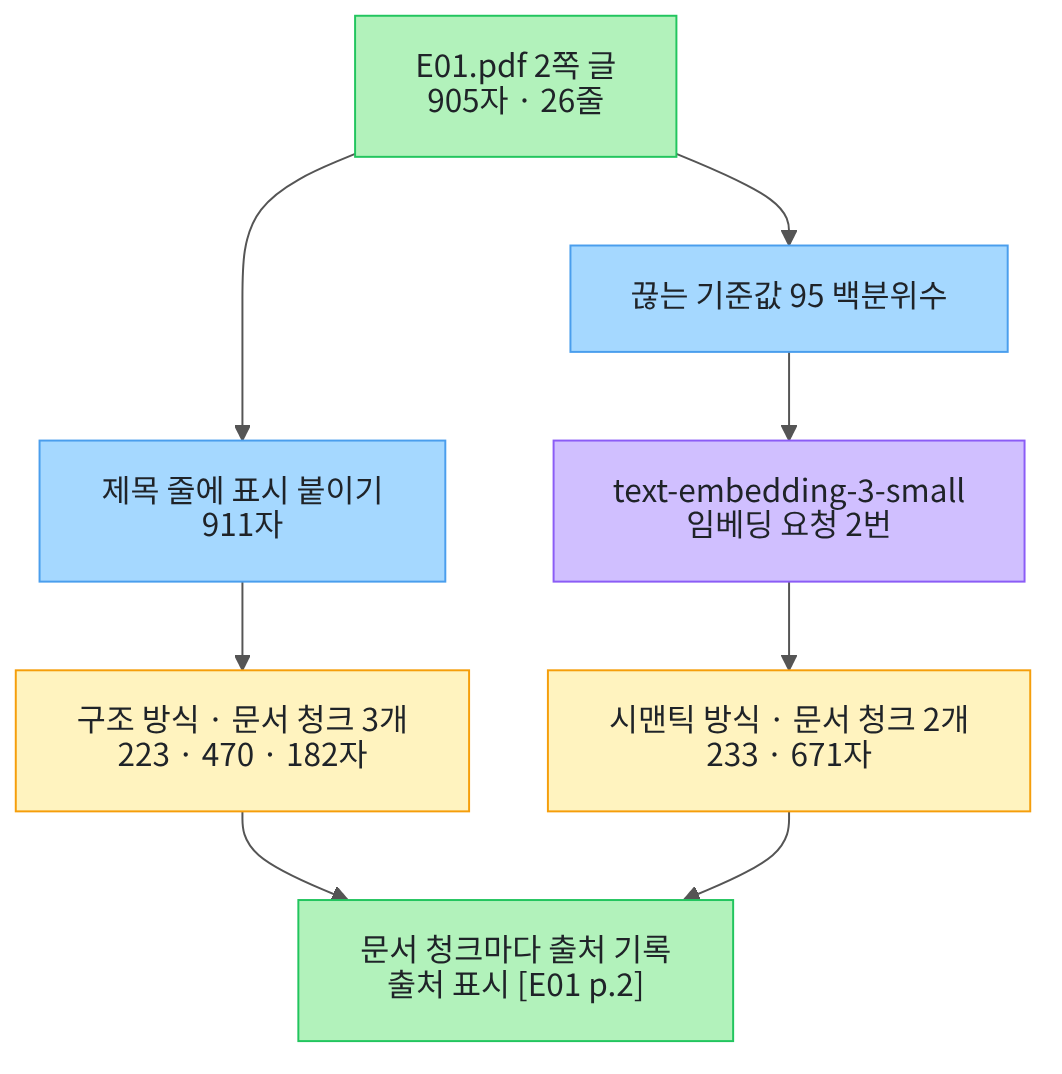

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
05절에서 쓴 나누기 도구에, 뜻으로 나누는 도구와 임베딩 도구를 더해 설치합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.18.0" "langchain-core==1.6.2" "langchain-text-splitters==1.1.2" "langchain-experimental==0.4.2" "langchain-openai==1.6.0" "tiktoken==0.14.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("langchain-experimental:", version("langchain-experimental"))
print("langchain-openai:", version("langchain-openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.18.0
langchain-core: 1.6.2
langchain-text-splitters: 1.1.2
langchain-experimental: 0.4.2
langchain-openai: 1.6.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 일곱 줄 가운데 첫 줄은 `pypdf: 6.18.0`입니다.
넷째 줄 `langchain-experimental: 0.4.2`와 다섯째 줄 `langchain-openai: 1.6.0`도 보세요.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
이름 `MarkdownHeaderTextSplitter`가 제목 표시를 보고 나누는 도구입니다.
이름 `SemanticChunker`가 이웃한 문장의 임베딩 거리로 나누는 도구입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 9 02·03절 `load_pdf_pages()`·`make_source_mark()`와 01절 `make_source_record()`를 가져옵니다.
05절 `make_length_list()`·`find_chunks_with_words()`와 Ch 8 01절 `count_tokens()`도 가져옵니다.

In [2]:
# 문서 객체·제목으로 나누기·뜻으로 나누기·임베딩·조각 세기에 쓸 이름을 불러옵니다
import os

from langchain_core.documents import Document
from langchain_text_splitters import MarkdownHeaderTextSplitter
from langchain_experimental.text_splitter import SemanticChunker
from langchain_openai import OpenAIEmbeddings
import tiktoken
# Ch 8 01절, Ch 9 02·03절, 01·05절 함수 여섯 개를 도구 파일에서 가져옵니다
from rag_tools import count_tokens, find_chunks_with_words, load_pdf_pages
from rag_tools import make_length_list, make_source_mark, make_source_record

[사용자 폴더]/tmp/ipykernel_340/3825521712.py:6: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.text_splitter import SemanticChunker


**결과 읽기** — 이 셀은 빨간 바탕에 경고를 출력합니다.
경고 글에 있는 `is being sunset`은 이 패키지를 더 이상 손보지 않는다는 예고입니다.
경고를 감추지 않고 그대로 두었습니다. 쓰는 사람이 알아야 하는 사실이기 때문입니다.
경고 앞에 붙은 임시 파일 경로는 실행할 때마다 달라집니다.

이 절은 그 패키지의 고정한 판으로 나누는 방법을 배우는 자리입니다.
새로 만드는 서비스에서 이 패키지를 골라도 된다는 뜻은 아닙니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.

## 2. 나눌 글 얻기

01~05절과 같은 방법으로 프로젝트 맨 위 경로를 고릅니다.
후보 세 개를 차례로 확인하고, 있는 경로에서 멈춥니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [4]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

준비 셀에서 가져온 Ch 9 02절 로더 함수 `load_pdf_pages()`는 PDF 경로와 문서 이름을 받아 쪽마다 `Document` 하나를 만듭니다.

다음 셀은 이 함수로 E01.pdf를 읽고 2쪽 본문을 나눌 글로 삼습니다.
05절과 같은 글이고 같은 이름 `plain_text`에 담습니다.
줄 목록도 함께 만듭니다. 제목 줄을 찾으려면 줄 단위로 봐야 하기 때문입니다.

In [5]:
# E01.pdf를 쪽마다 읽고 2쪽 본문과 그 줄 목록을 이 절에서 나눌 재료로 삼습니다
corpus_path = root_path + "/labs/data/rag-corpus"
pdf_path = corpus_path + "/pdf/easy/E01.pdf"
pages = load_pdf_pages(pdf_path, "E01")
plain_text = pages[1].page_content
text_lines = plain_text.split("\n")
print("나눌 글의 글자 수:", len(plain_text))
print("나눌 글의 줄 수:", len(text_lines))
print("첫 줄:", text_lines[0])
print("일곱째 줄:", text_lines[6])

나눌 글의 글자 수: 905
나눌 글의 줄 수: 26
첫 줄: 1. 도서관 소개
일곱째 줄: 2. 이용 시간


**결과 읽기** — 출력 첫 줄은 `나눌 글의 글자 수: 905`이고 다음 줄은 `나눌 글의 줄 수: 26`입니다.
셋째 줄은 `첫 줄: 1. 도서관 소개`이고 마지막 줄은 `일곱째 줄: 2. 이용 시간`입니다.
05절에서 본 값과 같은 글입니다.

번호가 붙은 두 줄이 이 글의 제목입니다. 그런데 제목임을 알리는 표시는 없습니다.
글자만 보면 본문 줄과 제목 줄이 똑같이 생겼습니다.

## 3. 제목 줄에 표시 붙이기

**제목 표시**는 그 줄이 제목임을 알리는 글입니다. Markdown에서는 `#`을 줄 앞에 붙입니다.
구조 방식 도구는 이 표시를 찾아 나누므로, 표시가 없는 글에서는 나눌 자리를 찾지 못합니다.

그래서 먼저 제목 줄을 찾아 표시를 붙입니다.
이 글의 제목 줄은 번호와 마침표로 시작하고 짧습니다.
그래서 「앞 세 글자에 마침표가 있고 스무 자보다 짧은 줄」을 제목 줄로 보기로 정했습니다.

In [6]:
# 줄 하나를 받아 제목 줄로 보이면 앞에 제목 표시를 붙여 반환합니다
def mark_heading_line(line):
    # 번호와 마침표로 시작하고 스무 자보다 짧은 줄을 제목 줄로 봅니다
    if "." in line[:3] and len(line) < 20:
        return "# " + line
    return line

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

이 규칙은 사람이 이 문서를 보고 정한 것입니다. 모든 문서에 쓰는 규칙이 아닙니다.
표 안의 행은 스무 자보다 길어서 제목 줄로 보지 않습니다.
다음 셀은 줄마다 이 함수를 불러 글 하나로 다시 이어 붙입니다.

In [7]:
# 줄 목록을 받아 제목 줄에 표시를 붙인 글 하나로 이어 붙여 반환합니다
def make_markdown_text(text_lines):
    markdown_text = ""
    for line in text_lines:
        marked_line = mark_heading_line(line)
        if markdown_text != "":
            markdown_text = markdown_text + "\n"
        markdown_text = markdown_text + marked_line
    return markdown_text

**결과 읽기** — 이 셀도 함수를 만들기만 하므로 출력이 없습니다.

줄 사이에는 줄바꿈 하나를 넣습니다. 02절 `make_row_text()`에서 칸 사이에 구분자를 넣은 모양과 같습니다.
첫 줄 앞에는 넣지 않으려고 글이 비었는지 먼저 봅니다.
다음 셀은 이 함수로 표시를 붙인 글을 만듭니다.

In [8]:
# 제목 줄에 표시를 붙인 글을 만들고 붙기 전후의 글자 수와 제목 줄을 봅니다
markdown_text = make_markdown_text(text_lines)
markdown_lines = markdown_text.split("\n")
print("표시를 붙인 뒤 글자 수:", len(markdown_text))
print("늘어난 글자 수:", len(markdown_text) - len(plain_text))
print("첫 줄:", markdown_lines[0])
print("일곱째 줄:", markdown_lines[6])
print("스물한째 줄:", markdown_lines[20])

표시를 붙인 뒤 글자 수: 911
늘어난 글자 수: 6
첫 줄: # 1. 도서관 소개
일곱째 줄: # 2. 이용 시간
스물한째 줄: # 3. 회원 가입


**결과 읽기** — 출력 첫 줄은 `표시를 붙인 뒤 글자 수: 911`이고 다음 줄은 `늘어난 글자 수: 6`입니다.
셋째 줄부터 세 줄은 `첫 줄: # 1. 도서관 소개`, `일곱째 줄: # 2. 이용 시간`, `스물한째 줄: # 3. 회원 가입`입니다.

제목 줄 세 개에 표시가 붙었습니다. 한 줄에 두 글자씩 늘어 모두 여섯 자가 늘었습니다.
본문 줄과 표의 행에는 표시가 붙지 않았습니다.

## 4. 구조 방식으로 나누기

**구조 방식**은 글에 있는 제목 표시를 보고 끊는 나누기입니다.
클래스 `MarkdownHeaderTextSplitter`가 그 방식을 맡습니다.
인자 `headers_to_split_on`에 「표시와 칸 이름」 짝의 목록을 줍니다.

05절 세 방식과 달리 목표 크기를 주지 않습니다. 끊는 자리는 글이 정하고 사람은 규칙만 줍니다.
먼저 문서 청크 목록에서 본문만 모으는 함수와 길이를 모으는 함수를 만듭니다.

In [9]:
# 문서 청크 Document 목록을 받아 본문 글만 순서대로 모아 반환합니다
def make_text_list(chunk_documents):
    chunk_texts = []
    for chunk in chunk_documents:
        chunk_texts.append(chunk.page_content)
    return chunk_texts

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

05절 검사 함수들은 글 목록을 받습니다. 이 절의 나누기 도구는 `Document` 목록을 반환합니다.
그래서 본문만 모아 두면 05절 함수를 그대로 쓸 수 있습니다.
문자 수는 준비 셀에서 가져온 05절 `make_length_list()`로 셉니다.

다음 셀은 표시 한 개를 `heading` 칸에 잇는 규칙으로 나눕니다.
칸 이름을 `heading`으로 둔 까닭은 04절이 `section` 칸을 자리 칸으로 이미 쓰고 있기 때문입니다.

In [10]:
# 제목 표시 한 개를 heading 칸에 잇는 규칙으로 나누고 문서 청크의 수와 길이를 봅니다
header_rules = [("#", "heading")]
structure_splitter = MarkdownHeaderTextSplitter(headers_to_split_on=header_rules)
structure_chunks = structure_splitter.split_text(markdown_text)
structure_texts = make_text_list(structure_chunks)
print("제목 표시와 칸 이름 규칙:", header_rules)
print("구조 방식 문서 청크 수:", len(structure_chunks))
print("문서 청크별 문자 수:", make_length_list(structure_texts))

제목 표시와 칸 이름 규칙: [('#', 'heading')]
구조 방식 문서 청크 수: 3
문서 청크별 문자 수: [223, 470, 182]


**결과 읽기** — 출력 첫 줄은 `제목 표시와 칸 이름 규칙: [('#', 'heading')]`입니다.
다음 줄은 `구조 방식 문서 청크 수: 3`이고 마지막 줄은 `문서 청크별 문자 수: [223, 470, 182]`입니다.

제목이 세 개라 문서 청크도 세 개입니다. 05절 두 방식은 같은 글에서 여섯 개였습니다.
길이는 182자부터 470자까지 벌어졌습니다. 목표 크기를 주지 않았으니 길이는 제목 사이의 글 길이 그대로입니다.

다음 셀은 문서 청크의 메타데이터와 본문 첫 줄을 봅니다.

In [11]:
# 문서 청크의 메타데이터와 제목 칸, 첫 문서 청크의 본문 첫 줄을 봅니다
first_structure = structure_chunks[0]
first_lines = first_structure.page_content.split("\n")
print("첫 문서 청크의 메타데이터:", first_structure.metadata)
print("문서 청크의 제목 칸:")
for chunk in structure_chunks:
    print(chunk.metadata["heading"])
print("첫 문서 청크의 첫 줄:", first_lines[0])

첫 문서 청크의 메타데이터: {'heading': '1. 도서관 소개'}
문서 청크의 제목 칸:
1. 도서관 소개
2. 이용 시간
3. 회원 가입
첫 문서 청크의 첫 줄: 미르시립도서관은 1998년 10월 미르시 중앙동에 문을 연 공공도서관입니다. 지상 4층, 지하 1층 규모


**결과 읽기** — 출력 첫 줄은 `첫 문서 청크의 메타데이터: {'heading': '1. 도서관 소개'}`입니다.
`문서 청크의 제목 칸:` 라벨 줄 아래 세 줄이 제목 세 개입니다.
마지막 줄 `첫 문서 청크의 첫 줄:` 뒤에는 도서관 소개 문장이 나옵니다.

제목 글은 본문에서 빠졌습니다. 그 대신 `heading` 칸에 남았습니다.
그래서 본문만 읽어도 어느 제목 아래에 있던 글인지 기록으로 알 수 있습니다.

메타데이터에는 제목 칸 하나뿐입니다. 01절 다섯 칸 기록은 따라오지 않았습니다.

## 5. 기록에 제목 칸 더하기

메서드 `split_text()`는 글 하나를 받으므로 파일 정보를 알지 못합니다.
그래서 05절처럼 출처 기록이 저절로 따라오지 않습니다.
준비 셀에서 가져온 01절 `make_source_record()`로 기록을 새로 붙입니다.

칸은 `doc_id`·`source`·`file_type`·`parser`·`page` 다섯 개입니다.
이 글도 01절과 같은 pypdf 기본 읽기로 얻었으니 `parser` 칸에 `pypdf-plain`을 적습니다.
출처 표시는 05절처럼 Ch 9 03절 `make_source_mark()`로 만듭니다. 이 함수는 `doc_id`와 `page` 두 칸만 읽습니다.
03절 `make_unit_mark()`와 04절 `make_section_mark()`는 쪽이 없는 형식에 쓰는 함수입니다.

다음 셀은 다섯 칸 기록에 제목 칸 하나를 더하는 함수를 만듭니다.
딕셔너리 `copy()`는 Ch 2에서 배운 메서드이고, 사본을 만들어야 문서 청크마다 다른 제목을 담을 수 있습니다.

In [12]:
# 쪽 기록의 사본에 제목 칸 하나를 더한 여섯 칸 기록을 만들어 반환합니다
def make_heading_record(page_record, heading):
    heading_record = page_record.copy()
    heading_record["heading"] = heading
    return heading_record

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

칸을 하나 더하는 모양은 03절 `csv_record["row"] = 2`와 같습니다.
그때는 자리 칸이었고 이번에는 제목 칸입니다.
다음 셀은 문서 청크마다 기록을 붙인 `Document`를 새로 만듭니다.

In [13]:
# 구조 방식 문서 청크마다 여섯 칸 기록을 붙인 Document를 새로 만듭니다
page_two_record = make_source_record(pdf_path, 2, "pypdf-plain")
heading_documents = []
for chunk in structure_chunks:
    heading_record = make_heading_record(page_two_record, chunk.metadata["heading"])
    heading_documents.append(Document(page_content=chunk.page_content, metadata=heading_record))
first_heading_document = heading_documents[0]
print("기록의 칸 수:", len(first_heading_document.metadata))
print("첫 문서 청크의 기록:", first_heading_document.metadata)
print("첫 문서 청크의 출처 표시:", make_source_mark(first_heading_document))
print("셋째 문서 청크의 제목 칸:", heading_documents[2].metadata["heading"])

기록의 칸 수: 6
첫 문서 청크의 기록: {'doc_id': 'E01', 'source': 'E01.pdf', 'file_type': 'pdf', 'parser': 'pypdf-plain', 'page': 2, 'heading': '1. 도서관 소개'}
첫 문서 청크의 출처 표시: [E01 p.2]
셋째 문서 청크의 제목 칸: 3. 회원 가입


**결과 읽기** — 출력 첫 줄은 `기록의 칸 수: 6`입니다.
다음 줄 `첫 문서 청크의 기록:` 뒤에는 `'parser': 'pypdf-plain'`과 `'heading': '1. 도서관 소개'`가 함께 보입니다.
셋째 줄은 `첫 문서 청크의 출처 표시: [E01 p.2]`이고 마지막 줄은 `셋째 문서 청크의 제목 칸: 3. 회원 가입`입니다.

다섯 칸에 제목 칸 하나가 더해져 여섯 칸이 되었습니다.
출처 표시는 01·02·05절과 같은 `[E01 p.2]`입니다. 세 문서 청크가 모두 한 쪽에서 나왔기 때문입니다.
쪽 안에서 어느 제목 아래였는지는 출처 표시가 아니라 `heading` 칸이 알려 줍니다.

## 6. 값 하나만 바꿔 보기

바꾸는 값은 규칙의 제목 표시 하나입니다. 표시 한 개를 두 개로 바꿉니다.
글과 칸 이름은 그대로 둡니다.

실행 전에 예상합니다. 이 글의 제목은 표시 한 개로 붙였으니 맞는 자리가 없을 것입니다.

In [14]:
# 규칙의 제목 표시만 두 개로 바꿔 같은 글을 다시 나눕니다
changed_rules = [("##", "heading")]
changed_splitter = MarkdownHeaderTextSplitter(headers_to_split_on=changed_rules)
changed_chunks = changed_splitter.split_text(markdown_text)
print("바꾼 규칙:", changed_rules)
print("문서 청크 수:", len(changed_chunks))
print("첫 문서 청크의 메타데이터:", changed_chunks[0].metadata)
print("첫 문서 청크의 문자 수:", len(changed_chunks[0].page_content))

바꾼 규칙: [('##', 'heading')]
문서 청크 수: 1
첫 문서 청크의 메타데이터: {}
첫 문서 청크의 문자 수: 911


**결과 읽기** — 출력 첫 줄은 `바꾼 규칙: [('##', 'heading')]`입니다.
다음 두 줄은 `문서 청크 수: 1`과 `첫 문서 청크의 메타데이터: {}`입니다.
마지막 줄은 `첫 문서 청크의 문자 수: 911`입니다.

끊긴 자리가 하나도 없어 글 전체가 문서 청크 하나가 되었습니다.
제목 칸도 비었습니다. 표시가 규칙과 맞지 않으면 제목을 찾지 못합니다.
구조 방식은 글의 표시와 규칙이 맞을 때만 나눈다는 뜻입니다.

## 7. 시맨틱 방식 준비

**시맨틱 방식**은 이웃한 문장의 임베딩 거리가 큰 자리에서 끊는 나누기입니다.
제목 표시가 없어도 쓸 수 있는 대신 임베딩 요청이 생깁니다.

먼저 Ch 9 03절과 같은 이름으로 임베딩 객체를 만듭니다.
모델 이름도 Ch 9와 같은 `text-embedding-3-small`입니다. 문서와 질문을 같은 자리에서 견주려면 같은 모델을 써야 합니다.
차원 수는 따로 주지 않습니다. Ch 9가 만든 색인과 같은 설정으로 이어 쓰려는 것입니다.

In [15]:
# Ch 9 03절과 같은 이름으로 임베딩 객체와 조각 세는 규칙을 준비합니다(요청은 보내지 않습니다)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
encoding = tiktoken.get_encoding("cl100k_base")
print("임베딩 모델 이름:", embedding_model.model)
print("조각 세는 규칙 이름:", encoding.name)

임베딩 모델 이름: text-embedding-3-small
조각 세는 규칙 이름: cl100k_base


**결과 읽기** — 출력 두 줄은 `임베딩 모델 이름: text-embedding-3-small`과 `조각 세는 규칙 이름: cl100k_base`입니다.

이 노트북의 임베딩 출력은 2026-09-21에 이 모델로 실행한 결과입니다.
임베딩 값은 실행마다 소수 아래 자리가 조금 달라질 수 있습니다. 그래서 나눈 결과를 `assert`로 검사하지 않았습니다.

조각 수는 준비 셀에서 가져온 `count_tokens()`에 조각 세는 규칙 `encoding`과 글을 넘겨 셉니다.

요청을 보내기 전에 얼마를 보내는지 어림합니다.
이 도구는 문장마다 앞뒤 문장을 함께 붙여 임베딩합니다. 그래서 보내는 조각 수가 글 전체의 세 배쯤 됩니다.
요금은 100만 토큰당 0.02달러입니다. 아주 작은 값이라 `round()`로 소수 일곱째 자리까지 줄입니다.

In [16]:
# 한 번의 요청에 보낼 조각 수와 그 비용을 요청 전에 어림합니다
whole_tokens = count_tokens(encoding, plain_text)
buffer_times = 3
sent_tokens = whole_tokens * buffer_times
embedding_rate = 0.02
tokens_per_million = 1000000
raw_cost = sent_tokens * embedding_rate / tokens_per_million
call_cost = round(raw_cost, 7)
print("나눌 글 전체의 조각 수:", whole_tokens)
print("한 번에 보낼 조각 수 어림:", sent_tokens)
print("요청 한 번의 비용 어림(달러):", call_cost)

나눌 글 전체의 조각 수: 869
한 번에 보낼 조각 수 어림: 2607
요청 한 번의 비용 어림(달러): 5.21e-05


**결과 읽기** — 출력 첫 줄은 `나눌 글 전체의 조각 수: 869`이고 05절에서 센 값과 같습니다.
다음 줄은 `한 번에 보낼 조각 수 어림: 2607`이고 마지막 줄은 `요청 한 번의 비용 어림(달러): 5.21e-05`입니다.

표기 `e-05`는 앞 수를 10으로 다섯 번 나눈 값이라는 뜻입니다. 곧 0.0000521달러입니다.
이 절은 요청을 두 번 보내므로 합쳐도 0.001달러보다 작습니다.
코드로 센 어림이고 청구 금액이 아닙니다.

## 8. 시맨틱 방식으로 나누기

클래스 `SemanticChunker`에 임베딩 객체를 넣어 스플리터를 만듭니다.
메서드 `split_documents()`에 `Document` 목록을 주면 다섯 칸 기록이 문서 청크마다 복사됩니다.
05절에서 정한 방법을 그대로 씁니다.

**끊는 기준값**은 거리가 이 값보다 크면 끊는다고 정한 값입니다.
백분위수로 줍니다. 백분위수는 값들을 작은 순서로 놓았을 때 그 비율 자리의 값입니다.
기본값 95는 거리 가운데 큰 쪽 5퍼센트만 끊는 자리로 고르겠다는 뜻입니다.

In [17]:
# 기본 기준값으로 같은 글을 이웃한 문장의 임베딩 거리로 나눕니다(임베딩 요청 1번)
page_two_document = Document(page_content=plain_text, metadata=page_two_record)
semantic_splitter = SemanticChunker(embedding_model)
semantic_chunks = semantic_splitter.split_documents([page_two_document])
semantic_texts = make_text_list(semantic_chunks)
second_lines = semantic_texts[1].split("\n")
print("기본 끊는 기준값:", semantic_splitter.breakpoint_threshold_amount)
print("시맨틱 방식 문서 청크 수:", len(semantic_chunks))
print("문서 청크별 문자 수:", make_length_list(semantic_texts))
print("첫 문서 청크의 기록 칸 수:", len(semantic_chunks[0].metadata))
print("둘째 문서 청크의 첫 줄:", second_lines[0])

기본 끊는 기준값: 95
시맨틱 방식 문서 청크 수: 2
문서 청크별 문자 수: [233, 671]
첫 문서 청크의 기록 칸 수: 5
둘째 문서 청크의 첫 줄: 2. 이용 시간


**결과 읽기** — 출력 첫 줄은 `기본 끊는 기준값: 95`입니다.
다음 두 줄은 `시맨틱 방식 문서 청크 수: 2`와 `문서 청크별 문자 수: [233, 671]`입니다.
넷째 줄은 `첫 문서 청크의 기록 칸 수: 5`이고 마지막 줄은 `둘째 문서 청크의 첫 줄: 2. 이용 시간`입니다.

끊은 자리가 한 곳입니다. 그 자리가 둘째 제목 바로 앞이었습니다.
제목 표시를 주지 않았는데도 구조 방식의 첫 끊는 자리와 같은 자리를 골랐습니다.

기록은 다섯 칸이 그대로 따라왔습니다. 제목 칸은 없습니다.
셋째 제목 앞에서는 끊지 않았습니다. 이번 실행에서는 그 자리의 거리가 기준값보다 크지 않았습니다.

## 9. 끊는 기준값 하나만 바꿔 보기

바꾸는 값은 끊는 기준값 하나입니다. 95를 50으로 낮춥니다.
글과 임베딩 모델은 그대로 둡니다.

기준값 50은 거리의 가운데 값입니다. 그보다 큰 거리가 모두 끊는 자리가 됩니다.
실행 전에 예상합니다. 끊는 자리가 늘어 문서 청크가 많아질 것입니다.

In [18]:
# 끊는 기준값만 50으로 낮춰 같은 글을 다시 나눕니다(임베딩 요청 1번)
lower_amount = 50
lower_splitter = SemanticChunker(embedding_model, breakpoint_threshold_amount=lower_amount)
lower_chunks = lower_splitter.split_documents([page_two_document])
lower_texts = make_text_list(lower_chunks)
print("바꾼 끊는 기준값:", lower_amount)
print("시맨틱 방식 문서 청크 수:", len(lower_chunks))
print("문서 청크별 문자 수:", make_length_list(lower_texts))
print("마지막 문서 청크:", lower_texts[9])

바꾼 끊는 기준값: 50
시맨틱 방식 문서 청크 수: 10
문서 청크별 문자 수: [102, 53, 28, 47, 79, 106, 403, 43, 34, 1]
마지막 문서 청크: 2


**결과 읽기** — 출력 첫 줄은 `바꾼 끊는 기준값: 50`이고 다음 줄은 `시맨틱 방식 문서 청크 수: 10`입니다.
셋째 줄은 `문서 청크별 문자 수: [102, 53, 28, 47, 79, 106, 403, 43, 34, 1]`입니다.
마지막 줄 `마지막 문서 청크: 2`를 보세요. 한 글자만 담긴 문서 청크입니다.

문서 청크가 두 개에서 열 개로 늘었습니다. 길이는 1자부터 403자까지 벌어졌습니다.
마지막 한 글자는 쪽 번호 줄입니다. 01절에서 본 것처럼 쪽 끝에는 쪽 번호가 한 줄로 남아 있습니다.

가장 긴 403자에는 표가 들어 있습니다. 표의 행에는 마침표가 없어 문장 하나로 묶였습니다.
문장 나누기 규칙이 마침표를 찾기 때문입니다.

## 10. 지킬 말 검사로 견주기

나눈 결과를 눈으로만 보지 않고 05절과 같은 검사로 확인합니다.
Ch 8 03절에서 정한 **지킬 말**을 씁니다. 사람이 원문에서 고른 꼭 남길 말입니다.
05절과 같은 `정기 휴관일`과 `화요일에도 휴관` 두 개를 씁니다.

검사에는 준비 셀에서 가져온 05절 `find_chunks_with_words()`를 씁니다.
문서 청크 글 목록에서 지킬 말이 모두 든 문서 청크의 번호를 1부터 세어 모읍니다.
함수 안에서는 Ch 8 03절 `find_missing_words()`가 빠진 말을 찾습니다.

다음 셀은 세 결과에서 지킬 말 두 개가 함께 든 자리를 찾습니다.

In [19]:
# 구조 방식과 두 기준값의 시맨틱 방식에서 지킬 말 두 개가 함께 든 문서 청크를 찾습니다
closure_words = ["정기 휴관일", "화요일에도 휴관"]
structure_found = find_chunks_with_words(structure_texts, closure_words)
semantic_found = find_chunks_with_words(semantic_texts, closure_words)
lower_found = find_chunks_with_words(lower_texts, closure_words)
print("지킬 말 두 개:", closure_words)
print("구조 방식에서 둘 다 든 문서 청크 번호:", structure_found)
print("시맨틱 방식 기준값 95에서:", semantic_found)
print("시맨틱 방식 기준값 50에서:", lower_found)

지킬 말 두 개: ['정기 휴관일', '화요일에도 휴관']
구조 방식에서 둘 다 든 문서 청크 번호: [2]
시맨틱 방식 기준값 95에서: [2]
시맨틱 방식 기준값 50에서: [6]


**결과 읽기** — 출력 둘째 줄은 `구조 방식에서 둘 다 든 문서 청크 번호: [2]`입니다.
셋째 줄은 `시맨틱 방식 기준값 95에서: [2]`이고 마지막 줄은 `시맨틱 방식 기준값 50에서: [6]`입니다.

세 결과 모두 지킬 말 두 개를 한 문서 청크에 담았습니다.
05절 재귀 방식에서는 두 말이 다른 문서 청크로 갈라졌습니다.

이 검사는 두 말이 한 문서 청크에 있는지만 봅니다. 답이 맞는지를 잰 값이 아닙니다.
글 하나와 지킬 말 두 개로 한 번 본 결과입니다. 어느 방식이 검색에 더 나은지는 이 절에서 재지 않았습니다.

## 11. 정리

1. pypdf 기본 읽기 글에는 제목 표시가 없어 제목 줄을 찾아 표시를 붙였습니다. 905자가 911자로 늘었습니다.
2. 구조 방식은 제목 세 개를 보고 문서 청크 3개를 만들었고 길이는 `[223, 470, 182]`였습니다.
3. 제목 글은 본문에서 빠져 `heading` 칸에 남았고, 01절 다섯 칸 기록을 붙여 여섯 칸이 되었습니다.
4. 규칙의 제목 표시를 두 개로 바꾸자 끊는 자리가 사라져 문서 청크가 하나였습니다.
5. 시맨틱 방식은 기준값 95에서 문서 청크 2개, 50에서 10개였고 첫 끊는 자리는 둘째 제목 앞이었습니다.
6. 세 결과 모두 지킬 말 두 개를 한 문서 청크에 담았습니다.

다음 07절에서는 문서 청크를 벡터로 바꾸는 단계를 따로 봅니다.
문장 하나와 문장 목록을 임베딩해 벡터의 숫자 개수를 보고, 같은 글을 두 번 보낼 때 값을 저장해 두는 방법을 봅니다.